### Build a Basic Chatbot with Langgraph (GRAPH API)

In [2]:
from typing import Annotated
from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages


In [3]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)

    messages: Annotated[list, add_messages]

graph_builder = StateGraph(State)

In [3]:
graph_builder

In [4]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [5]:
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain.chat_models import init_chat_model

llm = ChatGoogleGenerativeAI(
    model="gemini-3.1-flash-lite"
    )

In [12]:
llm

ChatGoogleGenerativeAI(metadata={'lc_versions': {'langchain-core': '1.8.1', 'langchain': '1.5.0', 'langchain-google-genai': '4.5.0'}}, profile={'name': 'Gemini 3.1 Flash Lite', 'release_date': '2026-05-07', 'last_updated': '2026-05-07', 'open_weights': False, 'max_input_tokens': 1048576, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': True, 'pdf_inputs': True, 'video_inputs': True, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'image_tool_message': True, 'tool_choice': True, 'reasoning_effort_levels': ['minimal', 'low', 'medium', 'high'], 'reasoning_effort_default': 'minimal'}, google_api_key=SecretStr('**********'), model='gemini-3.1-flash-lite', temperature=None, client=<google.genai.client.Client object at 0x0000020ACE62A210>, default_metadata=(), model_kwar

In [13]:
## Node Functionality

def chatbot(state: State):
    return {"messages": [llm.invoke(state["messages"])]}

In [14]:
graph_builder = StateGraph(State)

## Adding Nodes to the Graph
graph_builder.add_node("llmchatbot", chatbot)

## Adding Edges to the Graph
graph_builder.add_edge(START, "llmchatbot")
graph_builder.add_edge("llmchatbot", END)

## Combile the graph
graph = graph_builder.compile()

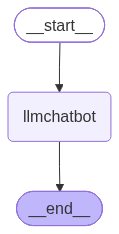

In [15]:
## Visualize the graph
from IPython.display import display, Image

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Graph visualization is not supported in this environment")
    print(f"Error: {e}")


In [17]:
response = graph.invoke({"messages": "Hello!"})

In [18]:
response

{'messages': [HumanMessage(content='Hello!', additional_kwargs={}, response_metadata={}, id='52375a47-8cc6-456a-90a4-bb707fbf59c9'),
  AIMessage(content=[{'type': 'text', 'text': 'Hello! How can I help you today?', 'extras': {'signature': 'EnMKcQFpFH0TO+DssoMOnFTX2EtyI57QKncHTj3fW1E1V5sgPMrmCFiCb8gPZzEUy0zGTD/VHQ2emowtrehnH6I+hVhtmNh3kuxH1O+KhbfMo+qXpIsWqHCG+T4UQe4OctMBMImspc+ikTqlhNgkW6rdQTHp'}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.1-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1e486-a682-7302-b928-e02332a2e5e5-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 3, 'output_tokens': 9, 'total_tokens': 12, 'input_token_details': {'cache_read': 0}})]}

In [20]:
response["messages"][0].content   ### Human Msg

'Hello!'

In [24]:
response["messages"][-1].content  ### LLM Msg

[{'type': 'text',
  'text': 'Hello! How can I help you today?',
  'extras': {'signature': 'EnMKcQFpFH0TO+DssoMOnFTX2EtyI57QKncHTj3fW1E1V5sgPMrmCFiCb8gPZzEUy0zGTD/VHQ2emowtrehnH6I+hVhtmNh3kuxH1O+KhbfMo+qXpIsWqHCG+T4UQe4OctMBMImspc+ikTqlhNgkW6rdQTHp'}}]

In [25]:
for event in graph.stream({"messages": "Konnichiwa!!, Hajimemashite"}):
    print(event)

{'llmchatbot': {'messages': [AIMessage(content=[{'type': 'text', 'text': 'Konnichiwa! Hajimemashite. Watashi wa AI desu. Yoroshiku onegaishimasu!\n\n(Hello! Nice to meet you. I am an AI. Pleased to meet you!)\n\nHow are you doing today? Is there anything you would like to talk about or practice in Japanese?', 'extras': {'signature': 'EnMKcQFpFH0T35j88PHMhzTTs770j+rRcV7VtU5pK244rzhxFypxTFIoR3Hr2aqrayeJ6D/AOvhmhFMwyF4Nv1zrgRl7Z1T/Ag3pTyxOtj9XKi3upxUkTyV0Xnmde9+Xah6LBG63WJ2Xul0ytId1v/LYBrn+'}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.1-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1e48a-4d66-72f4-bfe1-2668f0e1a44e-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 12, 'output_tokens': 68, 'total_tokens': 80, 'input_token_details': {'cache_read': 0}})]}}


In [26]:
for event in graph.stream({"messages": "Konnichiwa!!, Hajimemashite"}):
    for value in event.values():
        print(value)

{'messages': [AIMessage(content=[{'type': 'text', 'text': 'Konnichiwa! Hajimemashite. Watashi wa AI desu. Yoroshiku onegaishimasu!\n\n(Hello! Nice to meet you. I am an AI. Pleased to meet you!)\n\nHow are you doing today? Is there anything you would like to talk about or practice in Japanese?', 'extras': {'signature': 'EnMKcQFpFH0TBxwNnlBh0IhIvnYQoR9mwtOSasEZl8rSDL6UsJFfGa9Jv0fckuYqYo/Uaowa6niYQTvk17jqsKce1o9PKCIAKKUKTKE8HVb4JTRbaCDkU1vKjA1rbLhhdERrHqJvX0QZ89dJGtx2Yq3daiLH'}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.1-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1e48b-4011-7761-9cb8-f88d6a52f89a-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 12, 'output_tokens': 68, 'total_tokens': 80, 'input_token_details': {'cache_read': 0}})]}


### Chatbot With Tool

In [8]:
from langchain_tavily import TavilySearch

tool = TavilySearch(max_results= 2)
tool.invoke("What is the capital of France?")

{'query': 'What is the capital of France?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://en.wikipedia.org/wiki/Paris',
   'title': 'Paris - Wikipedia',
   'content': 'Paris is the capital and largest city of France, with an estimated city population of 2.04 million in an area of 105.4 km2 (40.7 sq mi), as of January 2026( and a metropolitan population of 13.3 million (2023). Located on the Seine in the centre of the Île-de-France region, it is the largest metropolitan area and fourth-most populous city in the European Union (EU). Paris is nicknamed the "City of Light" mainly due to its leading role in the Age of Enlightenment. [...] Appearance\n\nCoordinates: 48°51′24″N 2°21′08″E\ufeff / \ufeff48.8567°N 2.3522°E\ufeff / 48.8567; 2.3522_region:FR-75C)\n\nPage semi-protected\n\nFrom Wikipedia, the free encyclopedia\n\nCapital and largest city of France\n\nThis article is about the capital city of France. For other uses, see Paris (disambigua

In [7]:
## Custom Function

def multiply(a: int, b: int) -> int:
    """Multiply two integers and return the result.
    Args:
        a (int): The first integer.
        b (int): The second integer.
    
    Returns:
        int: The product of the two integers.
    """
    return a * b

In [9]:
tools = [tool, multiply]

In [10]:
llm_with_tool = llm.bind_tools(tools)

In [9]:
llm_with_tool

_ChatModelBinding(bound=ChatGoogleGenerativeAI(metadata={'lc_versions': {'langchain-core': '1.8.1', 'langchain': '1.5.0', 'langchain-google-genai': '4.5.0'}}, profile={'name': 'Gemini 3.1 Flash Lite', 'release_date': '2026-05-07', 'last_updated': '2026-05-07', 'open_weights': False, 'max_input_tokens': 1048576, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': True, 'pdf_inputs': True, 'video_inputs': True, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'image_tool_message': True, 'tool_choice': True, 'reasoning_effort_levels': ['minimal', 'low', 'medium', 'high'], 'reasoning_effort_default': 'minimal'}, google_api_key=SecretStr('**********'), model='gemini-3.1-flash-lite', temperature=None, client=<google.genai.client.Client object at 0x0000022C6C1BFE00>, default

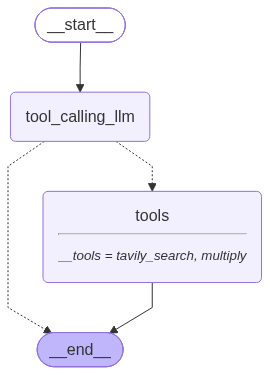

In [18]:
### Stategraph 
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition


### Node Def
def tool_calling_llm(state: State):
    return {"messages": [llm_with_tool.invoke(state["messages"])]}  
##Grph

builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools=tools))

## Adding Edges to the Graph
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools", END)

## Compile the graph
graph = builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [19]:
response = graph.invoke({"messages": "What is the today's AI news?"})
response

{'messages': [HumanMessage(content="What is the today's AI news?", additional_kwargs={}, response_metadata={}, id='50350591-8a55-493f-94de-4678d99d55d6'),
  AIMessage(content=[], additional_kwargs={'function_call': {'name': 'tavily_search', 'arguments': '{"search_depth": "advanced", "topic": "news", "query": "latest AI news today"}'}, '__gemini_function_call_thought_signatures__': {'call_14345499956517994235': 'EnMKcQFpFH0To0mpo6JOi85C4sgh4+PxGQE7mdwbzf/hRHyqMhlGsJZlB9Qp7Ik03RFoLmp9kaKjrPqJn+EhAi1//v0Z56cFiOOtDjCwgYT18MFlw8SabPfWtb2zfrziIpn4G0/pr1J9204+sF1EQ2E2B2eH'}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.1-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1e510-d0bc-7299-b0c8-e658f894ac71-0', tool_calls=[{'name': 'tavily_search', 'args': {'search_depth': 'advanced', 'topic': 'news', 'query': 'latest AI news today'}, 'id': 'call_14345499956517994235', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_t

In [20]:
response['messages'][-1].content ### LLM Msg

'{"query": "latest AI news today", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blog.google/innovation-and-ai/technology/ai/google-ai-updates-october-2026", "title": "The latest AI news we announced in October 2026", "content": "Put Gemini 4 Argon to work today, and see what’s next for Gemini 4 at the frontier. Following early safety testing, Gemini 4 Argon rolled out globally for complex coding, financial analysis, and legal workflows across Google AI Studio, the Gemini API, Google Cloud, Search, and the Gemini app, while also powering physical-world reasoning through Gemini 4 Argon for Robotics. Showing how quickly we’re pushing the frontier forward, two weeks later we announced Gemini 4 Carbon, our strongest model yet with state-of-the-art cybersecurity and long-horizon capabilities. Just as we did with Argon, we’re taking a deliberate approach to rollout: Carbon is now in pre-release testing with the U.S. government and a subset of trusted

In [21]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the today's AI news?
================================== Ai Message ==================================

[]
Tool Calls:
  tavily_search (call_14345499956517994235)
 Call ID: call_14345499956517994235
  Args:
    search_depth: advanced
    topic: news
    query: latest AI news today
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news today", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blog.google/innovation-and-ai/technology/ai/google-ai-updates-october-2026", "title": "The latest AI news we announced in October 2026", "content": "Put Gemini 4 Argon to work today, and see what’s next for Gemini 4 at the frontier. Following early safety testing, Gemini 4 Argon rolled out globally for complex coding, financial analysis, and legal workflows across Google AI Studio, the Gemini API, Goog

In [22]:
response = graph.invoke({"messages": "What is 8917643 multiplied by 12391?"})
response

{'messages': [HumanMessage(content='What is 8917643 multiplied by 12391?', additional_kwargs={}, response_metadata={}, id='73ca1da8-f0bd-418b-99a5-5c1fef6cacf3'),
  AIMessage(content=[], additional_kwargs={'function_call': {'name': 'multiply', 'arguments': '{"b": 12391, "a": 8917643}'}, '__gemini_function_call_thought_signatures__': {'call_12724530832206290744': 'EnMKcQFpFH0TIy8hYIUpKwYRmx+mlVrVMA4lTbI/+1nKlmVZQnMtWfWqQZNm6ibtQKfIddHTFi0H23SXgFL7kpVI7pWsVG9EAunlkHCTaCq+3WW4eiHdYPQBQLvxQ+aarVsrMD2Vj8E4WHx/Jrn1B0uq+pqh'}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.1-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1e513-1245-7787-a57c-e96991363777-0', tool_calls=[{'name': 'multiply', 'args': {'b': 12391, 'a': 8917643}, 'id': 'call_12724530832206290744', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 1588, 'output_tokens': 26, 'total_tokens': 1614, 'input_token_details': {'cache_read': 0}}),
  Too

In [23]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is 8917643 multiplied by 12391?
================================== Ai Message ==================================

[]
Tool Calls:
  multiply (call_12724530832206290744)
 Call ID: call_12724530832206290744
  Args:
    b: 12391
    a: 8917643
================================= Tool Message =================================
Name: multiply

110498514413


In [25]:
## Double tool call

response = graph.invoke({"messages": "What is 89 multiplied by 1291 and today's AI news?"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is 89 multiplied by 1291 and today's AI news?
================================== Ai Message ==================================

[]
Tool Calls:
  multiply (call_7779065318297064002)
 Call ID: call_7779065318297064002
  Args:
    b: 1291
    a: 89
  tavily_search (call_7779065318297065847)
 Call ID: call_7779065318297065847
  Args:
    topic: news
    time_range: day
    query: latest AI news today
================================= Tool Message =================================
Name: multiply

114899
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news today", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://ca.news.yahoo.com/latest-ai-china-tech-giant-112112680.html", "title": "The latest AI from China’s tech giant Baidu", "content": "Baidu CEO Robin Li is urging Chinese companies to embra

### ReAct Agent Architecture

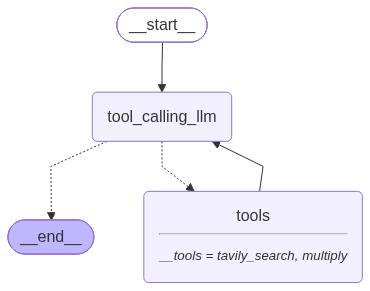

In [11]:
### Stategraph 
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition


### Node Def
def tool_calling_llm(state: State):
    return {"messages": [llm_with_tool.invoke(state["messages"])]}  
##Grph

builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools=tools))

## Adding Edges to the Graph
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools", "tool_calling_llm")

## Compile the graph
graph = builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [12]:
## Double tool call

response = graph.invoke({"messages": "What is 829 multiplied by 1291 and today's AI news?"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is 829 multiplied by 1291 and today's AI news?
================================== Ai Message ==================================

[]
Tool Calls:
  multiply (call_14808180152745657126)
 Call ID: call_14808180152745657126
  Args:
    b: 1291
    a: 829
  tavily_search (call_14808180152745660195)
 Call ID: call_14808180152745660195
  Args:
    time_range: day
    query: latest AI news today
================================= Tool Message =================================
Name: multiply

1070239
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news today", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://aiweekly.co/ai-news-today", "title": "AI News Today, November 16: Top Stories | AI Weekly", "content": "A new Childlight Global Child Safety Institute report finds reports of AI-generated child 

### Adding Memory In Agentic Graph

In [13]:
response = graph.invoke({"messages": "Hii My name is Fayash"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Hii My name is Fayash
================================== Ai Message ==================================

[{'type': 'text', 'text': "Hi Fayash! It's nice to meet you. How are you doing today? Is there anything I can help you with?", 'extras': {'signature': 'EpwBCpkBAWkUfRM3kG7hSqANFLm3FypMcP0Yu6BgShC6XIXT87fzNyD41Oa4FcggZ+Bc2feiY/Absxmv2klc1BQg2IGVmU3Olz/k9Rpxx1W0XjNYNbt5dO5F56mVVi+DeYJbDJ5SKdo0KUcHPQ79Ov8RMiOjEQclp+Ga+LnvQsw+SXrDCqn3qcKPk7ILmMV4MI/r0wAzVAdkGJsL+pnc'}}]


In [14]:
## Langgraph dont have memory, it will only respond to the current input.
response = graph.invoke({"messages": "What is my name?"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is my name?
================================== Ai Message ==================================

[{'type': 'text', 'text': "I do not know your name. As an AI, I don't have access to your personal information, identity, or private conversations unless you have previously shared that information with me in this specific chat session.", 'extras': {'signature': 'EpwBCpkBAWkUfRO075dL9bKKq7OwYJGEFq1dnysqmEeU52G7N07g/OejTl1BZIKjb28IEqy++pRUXUOSfA8JsGTbikdAP5gw9lwXUin0d2f2P6rqBZxXMcegzGJD6t8X47d1Xso/ZfiAcK5tyueMh9koF/yEr86uoEEA77Xgj67zHT3YKRCA1+jKfWWlpNIn9D9dxv3ZS8yAfTSue8rU'}}]


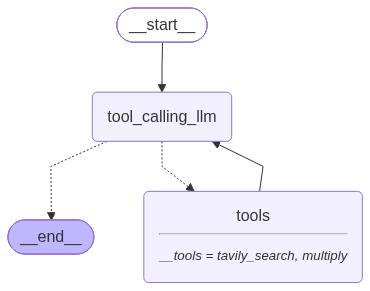

In [15]:
### Lets create a memory graph that can remember the previous messages and respond accordingly.
#  
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

### Node Def
def tool_calling_llm(state: State):
    return {"messages": [llm_with_tool.invoke(state["messages"])]}  
##Grph

builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools=tools))

## Adding Edges to the Graph
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools", "tool_calling_llm")


## Include memory while compiling
## Compile the graph
graph = builder.compile(checkpointer=memory)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [16]:
config = {"configurable": {"thread_id": "1"}}

response = graph.invoke({"messages": "Hii My name is Fayash"}, config=config)
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Hii My name is Fayash
================================== Ai Message ==================================

[{'type': 'text', 'text': "Hello, Fayash! It's nice to meet you. How are you doing today? Is there anything I can help you with?", 'extras': {'signature': 'EpwBCpkBAWkUfRPtLDB/Hl7K3Y9tLCVKkrb4XFXX4dtNFTEvw7sOQ177bjkTuhWJ8QVz0r0q9MCJ+4QBL6rGFBPYD4kxh22CXs3lWcLFll2feR0aitQEozulWE0H3jwXAalmXX4wFdPhwbgWa6wwdKs0M9ooL7tTNzv0tiezSvKUT1AfGOHxpoVwHYI5fOmQDPczCgzbRyvVwpF1zG5o'}}]


In [17]:
## Now lets check if the graph remembers the previous messages and responds accordingly.
response = graph.invoke({"messages": "What is my name?"}, config=config)
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Hii My name is Fayash
================================== Ai Message ==================================

[{'type': 'text', 'text': "Hello, Fayash! It's nice to meet you. How are you doing today? Is there anything I can help you with?", 'extras': {'signature': 'EpwBCpkBAWkUfRPtLDB/Hl7K3Y9tLCVKkrb4XFXX4dtNFTEvw7sOQ177bjkTuhWJ8QVz0r0q9MCJ+4QBL6rGFBPYD4kxh22CXs3lWcLFll2feR0aitQEozulWE0H3jwXAalmXX4wFdPhwbgWa6wwdKs0M9ooL7tTNzv0tiezSvKUT1AfGOHxpoVwHYI5fOmQDPczCgzbRyvVwpF1zG5o'}}]
================================ Human Message =================================

What is my name?
================================== Ai Message ==================================

[{'type': 'text', 'text': 'Your name is Fayash.', 'extras': {'signature': 'EpwBCpkBAWkUfRPn0fljuhjGqL+x4yacI7OK67DW2npBuL2I+2JXdIxcz2lbd7J3k3FFWULATnzEuNU/9xz+NuLBLhPgUURew9IB20Nc5Zxnq7VPi8bphx492e3DqOILcSY4HMDTq/Od0IopZOu5R6q04WMVg7TZGNuzZ4zN5rsSRbszmLEtOchKZ

### Streaming

In [18]:
from langgraph.checkpoint.memory import MemorySaver
memory = MemorySaver()

In [19]:
def superbot(state: State):
    return {"messages": [llm_with_tool.invoke(state["messages"])]}

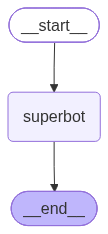

In [21]:
graph = StateGraph(State)

## node
graph.add_node("superbot", superbot)

## edges
graph.add_edge(START, "superbot")
graph.add_edge("superbot", END)

graph_builder = graph.compile(checkpointer=memory)

## Display the graph
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [22]:
### Invocation

config = {"configurable": {"thread_id": "1"}}

response = graph_builder.invoke({"messages": "Hii My name is Fayash and I like cinema"}, config=config) 

In [23]:
response

{'messages': [HumanMessage(content='Hii My name is Fayash and I like cinema', additional_kwargs={}, response_metadata={}, id='02620fba-11b1-4761-9b96-493fb1cf2fa0'),
  AIMessage(content=[{'type': 'text', 'text': 'Hi Fayash! It’s nice to meet you.\n\nSince you like cinema, I’d love to hear more about your taste! What kind of movies do you enjoy? Are you into any specific genres, directors, or perhaps you prefer classics over modern films?', 'extras': {'signature': 'EpwBCpkBAWkUfRNTsflu9QmGV/cZ4y+cCffAKtExf4bN0+OZ7xeXfkPq3cDP9inp+/WuqHGtNah7idjtZQ4DdQpS9/lmXwnJkrsRMB+usDwP1Ax+JfvRWIiCTcC2cm8Zg7fjGR3J9b3j9pMVY2J2BT/fNLW5a2/4tWFuIS0deBWbcYUHGSpAWm+pxxxuL6sdBbEnqn4KFvW1hplJoqB1'}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.1-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1e97a-238f-7164-a783-f1844299d2be-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1580, 'output_tokens': 55, '

### Streaming

Methods: .stream() and astream()

These methods are sync and async methods for streaming back results.
Additional parameters in streaming modes for graph state

- values : This streams the full state of the graph after each node is called.
- updates : This streams updates to the state of the graph after each node is called.

In [25]:
config = {"configurable": {"thread_id": "3"}}

for chunk in graph_builder.stream({"messages": "My name is Fayash and I like cinema and Anime"}, config=config, stream_mode="updates"):
    print(chunk)

### if mode = "updates", the stream will yield only the updated state after each node execution. We can only see AI message

{'superbot': {'messages': [AIMessage(content=[{'type': 'text', 'text': "Hello, Fayash! It’s nice to meet you.\n\nSince you're a fan of both cinema and anime, you must have a lot of great stories to explore. Do you have any favorite directors, genres, or specific films/series that you absolutely love? \n\nWhether you want to discuss classic films, talk about the latest anime releases, or get some recommendations for what to watch next, I'm here for it. What's currently on your watchlist?", 'extras': {'signature': 'EpwBCpkBAWkUfROBNl51PpD/1SJPxIhWcizbclITOINSKW1EZzr5kNAhwoW4KfuA61QaE9OUFiHrS/XgyKCMtKpQcAaLusnvsGKsNZW8hr4EQHjWPuwVG48pBY+J+uQp9nGAItTJiIi7nKRcOUo5bbHeye6xSfFSzbXpvI7mAQ72gc180kK/ubfrlOUorf94W2xqWvNEfGcrhaDkFVdp'}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.1-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1e97f-95f7-77a8-9e45-a88464ca99e2-0', tool_calls=[], invalid_tool_calls=[], usage_meta

In [26]:
for chunk in graph_builder.stream({"messages": "My name is Fayash and I like cinema and Anime"}, config=config, stream_mode="values"):
    print(chunk)

### If mode = "values", the stream will yield the entire state after each node execution. We can see both human and AI messages

{'messages': [HumanMessage(content='My name is Fayash and I like cinema and Anime', additional_kwargs={}, response_metadata={}, id='b2731eed-e7b7-4fd6-b2fb-a271eba15a01'), HumanMessage(content='My name is Fayash and I like cinema and Anime', additional_kwargs={}, response_metadata={}, id='103ac836-20ae-4c27-bbc5-dae81e0c032b'), AIMessage(content=[{'type': 'text', 'text': "Hello, Fayash! It’s nice to meet you.\n\nSince you're a fan of both cinema and anime, you must have a lot of great stories to explore. Do you have any favorite directors, genres, or specific films/series that you absolutely love? \n\nWhether you want to discuss classic films, talk about the latest anime releases, or get some recommendations for what to watch next, I'm here for it. What's currently on your watchlist?", 'extras': {'signature': 'EpwBCpkBAWkUfROBNl51PpD/1SJPxIhWcizbclITOINSKW1EZzr5kNAhwoW4KfuA61QaE9OUFiHrS/XgyKCMtKpQcAaLusnvsGKsNZW8hr4EQHjWPuwVG48pBY+J+uQp9nGAItTJiIi7nKRcOUo5bbHeye6xSfFSzbXpvI7mAQ72gc180k